# ELEC70143 In-Class Exercise — Air Pollution Monitoring (CO prediction)

Target: `CO(GT)` (mg/m³). Data: `q1.csv`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
TARGET = "CO(GT)"

In [ ]:
df = pd.read_csv("q1.csv")
FEATURES = [c for c in df.columns if c != TARGET]

SENSOR_COST = {
    "PT08.S1(CO)": 1000,
    "PT08.S2(NMHC)": 800,
    "PT08.S3(NOx)": 700,
    "PT08.S4(NO2)": 700,
    "PT08.S5(O3)": 900,
    "T": 150,
    "RH": 150,
    "AH": 200,
    "NOx(GT)": 1800,
    "NO2(GT)": 1800,
    "C6H6(GT)": 2500,
}

df.head()

## A. Missing data

- Report % missing per feature
- Propose and justify a strategy, then implement it

,missing %
NO2(GT),5.42
NOx(GT),5.38
PT08.S1(CO),4.30
C6H6(GT),4.30
PT08.S2(NMHC),4.30
PT08.S3(NOx),4.30
PT08.S4(NO2),4.30
PT08.S5(O3),4.30
T,4.30
RH,4.30


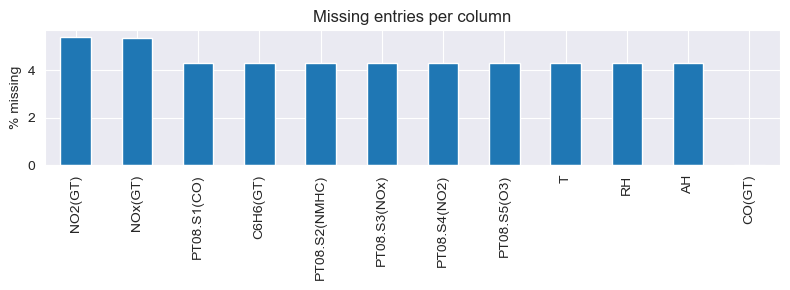

,n_rows,% rows
(none),6941,90.45
"NOx(GT), NO2(GT)",400,5.21
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), PT08.S3(NOx), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",317,4.13
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), NOx(GT), PT08.S3(NOx), NO2(GT), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",13,0.17
NO2(GT),3,0.04


Number of missing values per row:


0     6941
1        3
2      400
9      317
11      13
Name: count, dtype: int64

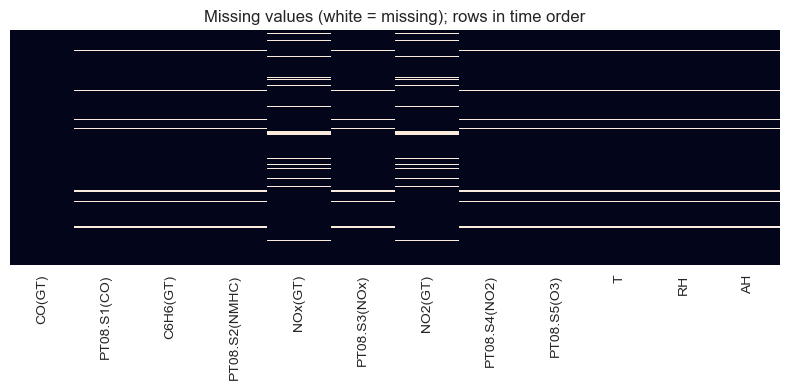

Device-offline rows: 330 in 13 contiguous blocks; longest block = 75 rows, median = 9 rows


,offline rows,other rows
count,330.000,7344.000
mean,2.665,2.130
std,1.710,1.436
min,0.300,0.100
25%,1.500,1.100
50%,2.200,1.800
75%,3.500,2.800
max,9.300,11.900
P(CO>5),0.100,0.042


Dropped 330 rows (4.30%); remaining = 7344


NOx(GT)    5.45
NO2(GT)    5.49
dtype: float64

Remaining NaNs after imputation: 0


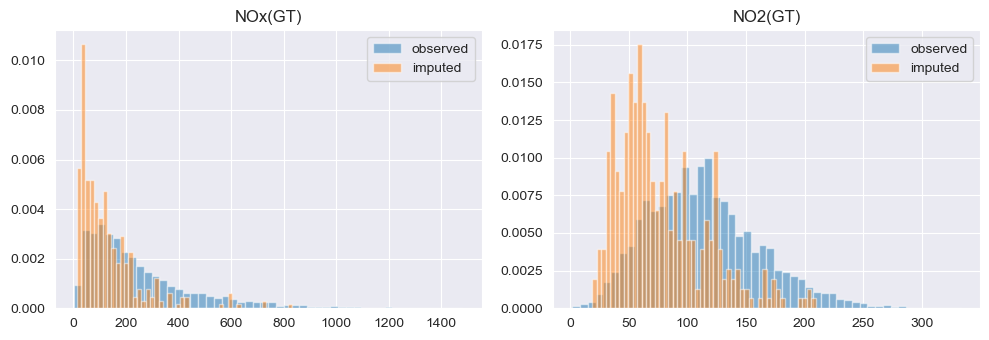

,before (observed),after (all rows)
NOx(GT),250.6,243.9
NO2(GT),113.9,111.9


In [3]:
# CELL1
missing_pct = df.isna().mean() * 100
missing_tbl = missing_pct.round(2).sort_values(ascending=False).to_frame("missing %")
display(missing_tbl)

missing_pct.sort_values(ascending=False).plot.bar(figsize=(8, 3))
plt.ylabel("% missing")
plt.title("Missing entries per column")
plt.tight_layout()
plt.show()

# CELL2
mask = df.isna()

pattern = mask.apply(lambda row: ", ".join(row[row].index) if row.any() else "(none)", axis=1)
pattern_counts = pattern.value_counts().to_frame("n_rows")
pattern_counts["% rows"] = (pattern_counts["n_rows"] / len(df) * 100).round(2)
display(pattern_counts)

print("Number of missing values per row:")
display(mask.sum(axis=1).value_counts().sort_index())


# CELL3
plt.figure(figsize=(8, 4))
sns.heatmap(mask, cbar=False, yticklabels=False)
plt.title("Missing values (white = missing); rows in time order")
plt.tight_layout()
plt.show()

offline = mask[FEATURES].sum(axis=1) >= 9          # all sensors + T/RH/AH missing
block_id = (offline != offline.shift()).cumsum()    # new id whenever the state changes
block_len = block_id[offline].value_counts()
print(f"Device-offline rows: {offline.sum()} in {len(block_len)} contiguous blocks; "
      f"longest block = {block_len.max()} rows, median = {int(block_len.median())} rows")

# CELL4
compare = pd.DataFrame({
    "offline rows": df.loc[offline, TARGET].describe(),
    "other rows": df.loc[~offline, TARGET].describe(),
})
compare.loc["P(CO>5)"] = [(df.loc[offline, TARGET] > 5).mean(), (df.loc[~offline, TARGET] > 5).mean()]
display(compare.round(3))

# CELL5
df_clean = df.loc[~offline].reset_index(drop=True)
print(f"Dropped {offline.sum()} rows ({offline.mean()*100:.2f}%); remaining = {len(df_clean)}")
display((df_clean.isna().mean() * 100).round(2)[lambda s: s > 0])

# CELL6
from sklearn.impute import KNNImputer

def knn_impute(fit_df, *other_dfs, cols=FEATURES, k=5):
    """Fit scaler + KNNImputer on fit_df[cols] only, then impute fit_df and any other_dfs.
    Scaling first because KNN uses Euclidean distance. The target is NOT used,
    since it would not be available at prediction time."""
    scaler = StandardScaler().fit(fit_df[cols])              # NaNs are ignored when fitting
    imputer = KNNImputer(n_neighbors=k).fit(scaler.transform(fit_df[cols]))

    out = []
    for d in (fit_df,) + other_dfs:
        d = d.copy()
        filled = imputer.transform(scaler.transform(d[cols]))
        d[cols] = scaler.inverse_transform(filled)           # back to original units
        out.append(d)
    return out[0] if len(out) == 1 else out

# For EDA (part B) we impute on the full cleaned data.
# NOTE: for modelling (part C onwards) refit the imputer on the TRAINING set only:
#   train_imp, test_imp = knn_impute(train_df, test_df)
df_imp = knn_impute(df_clean)
print("Remaining NaNs after imputation:", df_imp.isna().sum().sum())


# CELL7
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["NOx(GT)", "NO2(GT)"]):
    was_missing = df_clean[col].isna()
    ax.hist(df_clean[col].dropna(), bins=50, density=True, alpha=0.5, label="observed")
    ax.hist(df_imp.loc[was_missing, col], bins=50, density=True, alpha=0.5, label="imputed")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "before (observed)": df_clean[["NOx(GT)", "NO2(GT)"]].mean(),
    "after (all rows)": df_imp[["NOx(GT)", "NO2(GT)"]].mean(),
}).round(1))

**Discussion (A):**


## B. Distributions & correlations

- Correlation plot / pairs plot of main features + target
- Comment on strong correlations and multicollinearity

**Discussion (B):**


## C. Train/test split & OLS

- 80/20 random split
- statsmodels OLS with all features, summary, significant variables
- Why are some coefficients huge / p-values large?

In [5]:
# CELL1
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state = RANDOM_STATE)
train_imp, test_imp = knn_impute(train_df, test_df)

X_train,y_train = train_imp[FEATURES], train_imp[TARGET]
X_test,y_test = test_imp[FEATURES], test_imp[TARGET]

print(f"Train : {X_train.shape}, Test : {X_test.shape}")

# CELL2
X_train_c = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_c).fit()
print(ols.summary())

# CELL3 
# ---- C3. Significant variables (alpha = 0.05) ----
coef_tbl = pd.DataFrame({
    "coef": ols.params,
    "std err": ols.bse,
    "t": ols.tvalues,
    "p-value": ols.pvalues,
}).drop("const")
coef_tbl["significant (p<0.05)"] = coef_tbl["p-value"] < 0.05
display(coef_tbl.sort_values("p-value").round(5))

print("Significant:    ", list(coef_tbl.index[coef_tbl["significant (p<0.05)"]]))
print("Not significant:", list(coef_tbl.index[~coef_tbl["significant (p<0.05)"]]))

# CELL4
from statsmodels.stats.outliers_influence import variance_inflation_factor

# (i) Variance inflation factors (computed with the constant included)
vif = pd.Series(
    [variance_inflation_factor(X_train_c.values, i) for i in range(1, X_train_c.shape[1])],
    index=FEATURES, name="VIF",
)

# (ii) Sign of the marginal correlation with CO vs sign of the OLS coefficient
corr_with_y = X_train.corrwith(y_train)

# (iii) Feature scale: coefficient size depends on the units of each feature
diag = pd.DataFrame({
    "corr with CO": corr_with_y,
    "OLS coef": ols.params[FEATURES],
    "sign flipped": np.sign(corr_with_y) != np.sign(ols.params[FEATURES]),
    "VIF": vif,
    "feature std": X_train.std(),
    "coef x std": ols.params[FEATURES] * X_train.std(),   # effect of a 1-SD change
    "p-value": ols.pvalues[FEATURES],
})
display(diag.sort_values("VIF", ascending=False).round(4))
print(f"Condition number of X: {ols.condition_number:,.0f}")

Train : (5875, 11), Test : (1469, 11)
                            OLS Regression Results                            
Dep. Variable:                 CO(GT)   R-squared:                       0.910
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                     5365.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:43:02   Log-Likelihood:                -3441.6
No. Observations:                5875   AIC:                             6907.
Df Residuals:                    5863   BIC:                             6987.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const   

,coef,std err,t,p-value,significant (p<0.05)
C6H6(GT),0.11589,0.00487,23.79908,0.00000,True
NOx(GT),0.00156,0.00007,20.93501,0.00000,True
PT08.S1(CO),0.00133,0.00008,17.69145,0.00000,True
PT08.S4(NO2),0.00062,0.00007,9.28987,0.00000,True
NO2(GT),0.00224,0.00026,8.66662,0.00000,True
PT08.S5(O3),-0.00034,0.00004,-8.34146,0.00000,True
T,-0.01957,0.00241,-8.12043,0.00000,True
RH,-0.00440,0.00094,-4.70055,0.00000,True
PT08.S3(NOx),0.00018,0.00005,3.62410,0.00029,True
PT08.S2(NMHC),-0.00025,0.00017,-1.47095,0.14136,False


Significant:     ['PT08.S1(CO)', 'C6H6(GT)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH']
Not significant: ['PT08.S2(NMHC)', 'AH']


,corr with CO,OLS coef,sign flipped,VIF,feature std,coef x std,p-value
PT08.S2(NMHC),0.9147,-0.0003,True,63.9017,266.6152,-0.0668,0.1414
C6H6(GT),0.9304,0.1159,False,41.4382,7.5051,0.8698,0.0000
PT08.S4(NO2),0.6305,0.0006,False,17.0826,349.8625,0.2180,0.0000
T,0.0209,-0.0196,True,14.4003,8.9402,-0.1749,0.0000
AH,0.0517,-0.0339,True,10.8340,0.4008,-0.0136,0.4673
PT08.S5(O3),0.8530,-0.0003,True,8.5592,407.6323,-0.1386,0.0000
PT08.S1(CO),0.8786,0.0013,False,8.3544,218.3340,0.2903,0.0000
RH,0.0507,-0.0044,True,8.3252,17.5139,-0.0770,0.0000
NOx(GT),0.7965,0.0016,False,7.5172,209.1199,0.3259,0.0000
PT08.S3(NOx),-0.6994,0.0002,True,5.0432,258.6633,0.0462,0.0003


Condition number of X: 60,835


**Discussion (C):**


## D. Ridge & Lasso (CV-tuned, scaled features)

- Tune regularisation parameter by CV
- Coefficient paths vs. regularisation parameter (log scale)
- Effect on multicollinearity and interpretability

**Discussion (D):**


## E. Performance comparison

- In-sample and out-of-sample R², MAE, RMSE for OLS / Ridge / Lasso
- Pros and cons: performance vs. interpretability

**Discussion (E):**


## F. Cost–accuracy frontier

- Lasso path over a grid (e.g. 1e-6 to 1)
- For each: selected features, total cost, 5-fold CV RMSE on training data
- Plot Cost vs. RMSE
- Low-cost design (≤ £2500) and high-performance design (≤ £4000); test-set RMSE

**Discussion (F):**


## G. Alert threshold

- Legal threshold y = 5 mg/m³; FP = £2,000, FN = £10,000
- Alert if prediction > t; expected cost vs. t via CV
- Choose a threshold

In [ ]:
CO_LIMIT = 5.0
COST_FP = 2000
COST_FN = 10000


**Discussion (G):**


## H. Low-cost vs. high-performance: expected cost

- Compare expected cost of the two designs
- Are the extra sensors justified?

**Discussion (H):**
